In [52]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

## 5.1

In [53]:
a = -1.0
b =  1.0
i =  np.arange(1, 21)
N = 2 ** i


def trapezoidal(f, N, a, b):
    h_i = np.linspace(a, b, N + 1)
    h = (b - a) / N

    left = f(a) / 2
    middle = np.sum(f(h_i[1:-1]))
    right = f(b) / 2

    return h * (left + middle + right)

In [54]:
f1 = lambda x: np.pow(x, 2)
f2 = lambda x: np.abs(x)
f3 = lambda x: np.where(x < 1/3, np.exp(x) / 2, np.exp(x))
f4 = lambda x: np.sin(np.pi * x)
f5 = lambda x: np.sin(4 * np.pi * x)
f6 = lambda x: np.exp(x)
f7 = lambda x: np.where(x <= 1/2, np.exp(x) / 2, np.exp(x))

exact = np.array([
    2/3,
    1.0,
    0.5 * (np.exp(1/3) - np.exp(-1)) + (np.e - np.exp(1/3)),
    0.0,
    0.0,
    np.e - np.exp(-1),
    0.5 * (np.exp(1/2) - np.exp(-1)) + (np.e - np.exp(1/2))
])

In [55]:
integrals = np.array([[trapezoidal(f, n, a, b) for n in N] for f in (f1, f2, f3, f4, f5, f6, f7)])
errors = np.abs(integrals - exact[:, None])

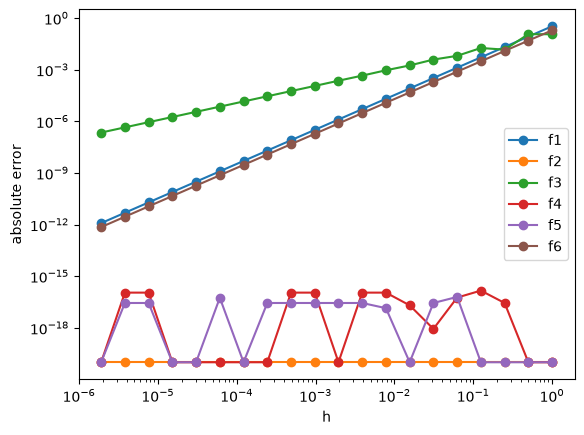

In [57]:
h = (b - a) / N
names = ["f1", "f2", "f3", "f4", "f5", "f6", "f7"]

for k in range(6):
    err = np.maximum(errors[k], 1e-20)
    plt.loglog(h, err, "o-", label=names[k])

plt.xlabel("h")
plt.ylabel("absolute error")
plt.legend()
plt.show()

on the graphic we can see that error of trapezoidal rule aproximation of integral is a line in loglog
h = (b - a) * 2**-i  
log h = -iC - linear func

so h from pow 0 to -6, err from 0 to -12  -> err is smth like = C * 2**(-2i) 
err ~= Ch²

for f2 err = 0 for all h, because f2 is symmetric and h dirive [a , b] into to symmetric parts which are
linear -> trapezoidal rule gives real value 

for f3 same as f1 is linear on the graphic -> err = Ch 
however we can see that f6 = e*\*x have err = Ch*\*2
the reason is that in point x = 1/3 we will always get error because it does not in h_i 